### This is the code for meta-analysis

Loaded 1271 rows, 125 unique studies.

=== P574L: 11 studies (after collapsing) ===
    pmid  country      x      n  n_timepoints
40681807 Ethiopia  2.300  901.0            17
39367758   Rwanda 24.039 4401.0             2
41305330   Rwanda  1.000  250.0             1
27573632   Rwanda  1.000   66.0             1
32747827   Rwanda  2.000  927.0             1
33864801   Rwanda  2.000  133.0             2
34216470   Rwanda  1.000  184.0             1
34279219   Rwanda  1.000  927.0             1
38196592   Rwanda  2.000  135.0             1
38746440 Tanzania  2.160  120.0             1
31358588   Uganda  1.000   66.0             1

Pooled prevalence: 0.3% (95% CI 0.1-0.6%)
tau^2 = 0.0003, I^2 = 41.0%, Q(10) = 17.0, p_het = 0.07536
Forest plot saved to forest_P574L_1.png

=== P574L: country subgroups ===
 country  k_studies  pooled  prevalence_pct    ci_lo    ci_hi    I2_pct    tau2
Tanzania          1   False        1.800000      NaN      NaN       NaN     NaN
  Uganda          1   False 

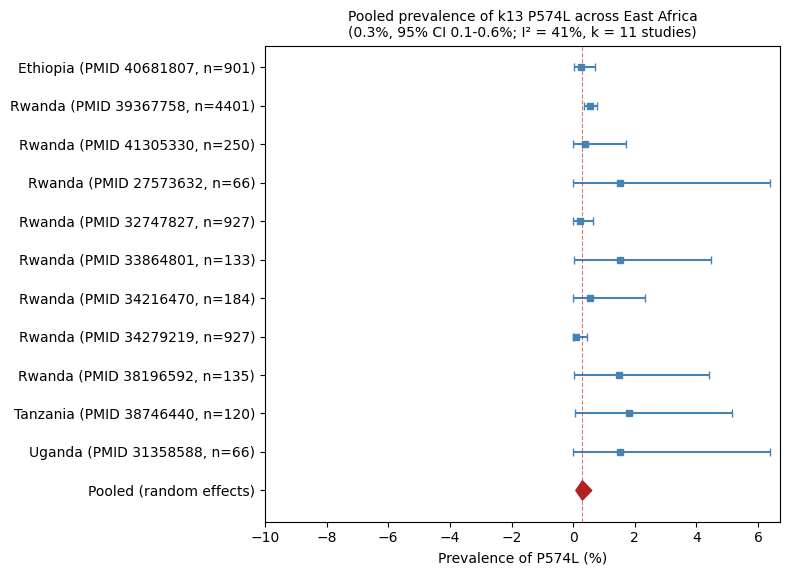

In [6]:
"""
k13_meta_analysis.py
---------------------
Self-contained script: loads the k13 validated-mutations dataset, cleans it,
and runs a random-effects meta-analysis of proportions (pooled prevalence)
for one mutation at a time, with a forest plot.

Everything is in ONE file on purpose -- no other local modules needed.
Just put this script and your Excel file in the same folder and run it.

Method: Freeman-Tukey double arcsine transformation (Freeman & Tukey, 1950)
with DerSimonian-Laird (1986) random-effects pooling, back-transformed using
the harmonic-mean method of Miller (1978). This mirrors R's
meta::metaprop(sm="PFT", method.tau="DL").
"""

import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# =================================================================
# SETTINGS -- change these two lines as needed
# =================================================================
RAW_PATH = "K13_validated_v8.xlsx"   # must be in the same folder as this script
MUTATION = "P574L"                    # change to "A675V", "R561H", "C469Y", "R622I", "P574L", etc.


# =================================================================
# STEP 1-2: Load raw data
# =================================================================
def load_raw(path=RAW_PATH):
    return pd.read_excel(path, sheet_name="Sheet1")


# =================================================================
# STEP 3: Clean year_sample into a single numeric year
# =================================================================
def parse_year(val):
    """Return the mean of all 4-digit years found in a year_sample field."""
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if s.lower() == "missing":
        return np.nan
    s = s.replace("\u2013", "-").replace("\u2014", "-")
    years = [int(y) for y in re.findall(r"(?:19|20)\d{2}", s)]
    if not years:
        return np.nan
    return sum(years) / len(years)


# =================================================================
# STEP 4: Clean numerator/denominator (shared by all downstream steps)
# =================================================================
def clean_data(df):
    df = df.copy()
    df["year_sample_clean"] = df["year_sample"].apply(parse_year)
    df["samples_genotyped"] = pd.to_numeric(df["samples_genotyped"], errors="coerce")
    df["raw_count"] = pd.to_numeric(df["raw_count"], errors="coerce")

    mut = df["k13_validated_mutations"].astype(str).str.strip()
    valid_mut = ~mut.isin(["-", "0", "-\t", "nan"])
    has_counts = (
        df["raw_count"].notna()
        & df["samples_genotyped"].notna()
        & (df["samples_genotyped"] > 0)
    )
    clean = df[valid_mut & has_counts].copy()
    clean["k13_validated_mutations"] = mut[valid_mut & has_counts]
    return clean


# =================================================================
# STEP 5: Collapse to one row per study per mutation (for Steps 7-9)
# =================================================================
def study_level_table(clean, mutation):
    sub = clean[clean["k13_validated_mutations"] == mutation]
    table = sub.groupby("pmid").agg(
        country=("country", "first"),
        x=("raw_count", "sum"),
        n=("samples_genotyped", "sum"),
        year_mid=("year_sample_clean", "mean"),
        n_timepoints=("raw_count", "size"),
    ).reset_index()
    return table.sort_values("country").reset_index(drop=True)


def clean_and_collapse(df, mutation):
    """Convenience wrapper kept for backward compatibility: clean the raw
    dataframe and collapse to one row per study for the given mutation."""
    clean = clean_data(df)
    return study_level_table(clean, mutation)


# =================================================================
# STEP 7: Meta-analysis of proportions (Freeman-Tukey + DerSimonian-Laird)
# =================================================================
def freeman_tukey_transform(x, n):
    x = np.asarray(x, dtype=float)
    n = np.asarray(n, dtype=float)
    phi = 0.5 * (np.arcsin(np.sqrt(x / (n + 1))) +
                 np.arcsin(np.sqrt((x + 1) / (n + 1))))
    var_phi = 1.0 / (4.0 * n + 2.0)
    return phi, var_phi


def back_transform_pft(phi, n_harmonic):
    # The double-arcsine transform of a proportion x/n is only ever defined
    # for x between 0 and n. That means, for a given (harmonic-mean) n, phi
    # itself has an achievable floor (x=0) and ceiling (x=n) -- phi values
    # outside that range cannot correspond to any real proportion for that n.
    # A pooled or CI value can land outside this range (e.g. the lower CI
    # bound pushed below the x=0 floor by high between-study variance), and
    # the general Miller (1978) formula becomes numerically unstable there
    # (it can return values like 0.5 instead of ~0). We clamp to the
    # achievable range first, which is both the correct interpretation (a
    # proportion can't be estimated more precisely than "close to 0/1") and
    # numerically stable.
    phi_floor = 0.5 * np.arcsin(np.sqrt(1.0 / (n_harmonic + 1)))          # x=0
    phi_ceiling = 0.5 * (np.arcsin(np.sqrt(n_harmonic / (n_harmonic + 1))) + np.pi / 2)  # x=n

    if phi <= phi_floor:
        return 0.0
    if phi >= phi_ceiling:
        return 1.0

    sin2t = np.sin(2 * phi)
    inner = sin2t + (sin2t - 1.0 / sin2t) / n_harmonic
    inner = np.clip(inner, -1, 1)
    return 0.5 * (1 - np.sign(np.cos(2 * phi)) * np.sqrt(1 - inner ** 2))


def dersimonian_laird(phi, var_phi):
    k = len(phi)
    w_fixed = 1.0 / var_phi
    mean_fixed = np.sum(w_fixed * phi) / np.sum(w_fixed)

    Q = np.sum(w_fixed * (phi - mean_fixed) ** 2)
    df = k - 1
    C = np.sum(w_fixed) - np.sum(w_fixed ** 2) / np.sum(w_fixed)
    tau2 = max(0.0, (Q - df) / C) if C > 0 else 0.0

    w_random = 1.0 / (var_phi + tau2)
    pooled_phi = np.sum(w_random * phi) / np.sum(w_random)
    se_pooled_phi = np.sqrt(1.0 / np.sum(w_random))

    I2 = max(0.0, (Q - df) / Q) * 100 if Q > 0 else 0.0
    p_het = 1 - stats.chi2.cdf(Q, df) if df > 0 else np.nan

    return {
        "k": k, "pooled_phi": pooled_phi, "se_pooled_phi": se_pooled_phi,
        "tau2": tau2, "Q": Q, "df": df, "I2": I2, "p_heterogeneity": p_het,
        "weights_random": w_random,
    }


def metaprop(x, n, ci_level=0.95):
    x = np.asarray(x, dtype=float)
    n = np.asarray(n, dtype=float)

    phi, var_phi = freeman_tukey_transform(x, n)
    res = dersimonian_laird(phi, var_phi)

    z = stats.norm.ppf(0.5 + ci_level / 2)
    phi_lo = res["pooled_phi"] - z * res["se_pooled_phi"]
    phi_hi = res["pooled_phi"] + z * res["se_pooled_phi"]

    n_harm = stats.hmean(n)
    pooled_p = back_transform_pft(res["pooled_phi"], n_harm)
    ci_lo = back_transform_pft(phi_lo, n_harm)
    ci_hi = back_transform_pft(phi_hi, n_harm)

    study_p = np.array([back_transform_pft(p, ni) for p, ni in zip(phi, n)])
    study_se_phi = np.sqrt(var_phi)
    study_lo = np.array([back_transform_pft(p - z * se, ni)
                          for p, se, ni in zip(phi, study_se_phi, n)])
    study_hi = np.array([back_transform_pft(p + z * se, ni)
                          for p, se, ni in zip(phi, study_se_phi, n)])

    return {
        "x": x, "n": n,
        "study_p": study_p, "study_lo": study_lo, "study_hi": study_hi,
        "pooled_p": pooled_p, "ci_lo": ci_lo, "ci_hi": ci_hi,
        "tau2": res["tau2"], "I2": res["I2"], "Q": res["Q"], "df": res["df"],
        "p_heterogeneity": res["p_heterogeneity"], "k": res["k"],
    }


# =================================================================
# STEP 8: Forest plot
# =================================================================
def forest_plot(table, result, mutation):
    k = result["k"]
    fig, ax = plt.subplots(figsize=(8, 0.35 * k + 2))

    y_pos = np.arange(k, 0, -1)
    study_labels = [f"{row.country} (PMID {row.pmid}, n={int(row.n)})"
                    for row in table.itertuples()]

    lo_err = np.clip((result["study_p"] - result["study_lo"]) * 100, 0, None)
    hi_err = np.clip((result["study_hi"] - result["study_p"]) * 100, 0, None)
    ax.errorbar(
        result["study_p"] * 100, y_pos,
        xerr=[lo_err, hi_err],
        fmt="s", color="steelblue", ecolor="steelblue", capsize=3, markersize=5,
        label="Study estimate (95% CI)",
    )

    pooled_y = 0
    diamond_x = [result["ci_lo"] * 100, result["pooled_p"] * 100,
                 result["ci_hi"] * 100, result["pooled_p"] * 100]
    diamond_y = [pooled_y, pooled_y + 0.25, pooled_y, pooled_y - 0.25]
    ax.fill(diamond_x, diamond_y, color="firebrick")

    ax.set_yticks(list(y_pos) + [pooled_y])
    ax.set_yticklabels(study_labels + ["Pooled (random effects)"])
    ax.axvline(result["pooled_p"] * 100, color="firebrick", linestyle="--",
               linewidth=0.8, alpha=0.6)
    ax.set_xlabel(f"Prevalence of {mutation} (%)")
    ax.set_title(
        f"Pooled prevalence of k13 {mutation} across East Africa\n"
        f"({result['pooled_p']*100:.1f}%, 95% CI {result['ci_lo']*100:.1f}-"
        f"{result['ci_hi']*100:.1f}%; I\u00b2 = {result['I2']:.0f}%, k = {k} studies)",
        fontsize=10,
    )
    ax.set_xlim(left=-10)
    plt.tight_layout()
    outname = f"forest_{mutation}_1.png"
    plt.savefig(outname, dpi=200)
    print(f"Forest plot saved to {outname}")


# =================================================================
# STEP 9: Country-subgroup pooling + test for subgroup differences
# =================================================================
MIN_STUDIES_TO_POOL = 3  # countries with fewer studies are reported descriptively only


def subgroup_by_country(table, min_studies=MIN_STUDIES_TO_POOL):
    """Run a separate metaprop() within each country that has enough studies.

    Countries with fewer than `min_studies` studies are still returned (so you
    can see their raw data) but are flagged as not pooled -- their single-study
    or two-study "prevalence" would be unstable and is not a meta-analytic
    estimate.

    Returns a DataFrame with one row per country.
    """
    rows = []
    for country, sub in table.groupby("country"):
        x = sub["x"].values
        n = sub["n"].values
        k = len(sub)
        if k >= min_studies:
            res = metaprop(x, n)
            rows.append({
                "country": country, "k_studies": k, "pooled": True,
                "prevalence_pct": res["pooled_p"] * 100,
                "ci_lo": res["ci_lo"] * 100, "ci_hi": res["ci_hi"] * 100,
                "I2_pct": res["I2"], "tau2": res["tau2"],
            })
        else:
            # descriptive only: naive combined proportion, no valid CI/I2
            naive_p = 100 * x.sum() / n.sum()
            rows.append({
                "country": country, "k_studies": k, "pooled": False,
                "prevalence_pct": naive_p,
                "ci_lo": np.nan, "ci_hi": np.nan,
                "I2_pct": np.nan, "tau2": np.nan,
            })
    return pd.DataFrame(rows).sort_values("prevalence_pct", ascending=False).reset_index(drop=True)


def subgroup_heterogeneity_test(table):
    """Fixed-effect Q-test for whether pooled prevalence differs across
    country subgroups (analogous to a one-way ANOVA in meta-analysis).

    Q_between = Q_total - Q_within, tested against a chi-square distribution
    with (number of countries - 1) degrees of freedom.

    Note: countries with only 1 study contribute 0 to Q_within (df = 0) but
    are still included in Q_total and in the group count -- this is standard,
    but the test is more reliable when most subgroups have >=2 studies.
    """
    phi, var_phi = freeman_tukey_transform(table["x"].values, table["n"].values)
    w = 1.0 / var_phi

    grand_mean = np.sum(w * phi) / np.sum(w)
    Q_total = np.sum(w * (phi - grand_mean) ** 2)

    Q_within = 0.0
    df_within = 0
    countries = table["country"].unique()
    table = table.copy()
    table["_phi"] = phi
    table["_w"] = w

    for country in countries:
        sub = table[table["country"] == country]
        if len(sub) < 2:
            continue  # 0 degrees of freedom, contributes 0 to Q_within
        mean_g = np.sum(sub["_w"] * sub["_phi"]) / np.sum(sub["_w"])
        Q_within += np.sum(sub["_w"] * (sub["_phi"] - mean_g) ** 2)
        df_within += len(sub) - 1

    Q_between = Q_total - Q_within
    df_between = len(countries) - 1
    p_between = 1 - stats.chi2.cdf(Q_between, df_between) if df_between > 0 else np.nan

    return {
        "Q_between": Q_between, "df_between": df_between, "p_between": p_between,
        "Q_within": Q_within, "df_within": df_within,
        "n_countries": len(countries),
    }


def country_forest_plot(table, mutation, min_studies=MIN_STUDIES_TO_POOL):
    """Forest plot grouped by country, with a pooled diamond per country
    that has enough studies, plus the overall pooled diamond at the bottom."""
    table = table.copy()
    # order countries by their (pooled or naive) prevalence, descending
    country_summary = subgroup_by_country(table, min_studies)
    country_order = country_summary["country"].tolist()

    table["_country_rank"] = table["country"].map({c: i for i, c in enumerate(country_order)})
    table = table.sort_values(["_country_rank", "n"], ascending=[True, False]).reset_index(drop=True)

    overall = metaprop(table["x"].values, table["n"].values)

    # build the y-axis: each study row, plus a subgroup-pooled diamond row
    # after each country's studies, plus the overall diamond at the very bottom
    y = 0
    y_positions, labels, kinds = [], [], []  # kinds: "study" or "diamond"
    diamonds = []  # (y, lo, mid, hi) for country diamonds
    study_rows = []  # indices into table, in plotted order

    for country in country_order:
        sub = table[table["country"] == country]
        for idx in sub.index:
            y += 1
            y_positions.append(y)
            labels.append(f"  {sub.loc[idx, 'country']} (PMID {sub.loc[idx, 'pmid']}, n={int(sub.loc[idx, 'n'])})")
            kinds.append("study")
            study_rows.append(idx)
        y += 1
        row = country_summary[country_summary["country"] == country].iloc[0]
        if row["pooled"]:
            diamonds.append((y, row["ci_lo"], row["prevalence_pct"], row["ci_hi"]))
            labels.append(f"  {country} subgroup pooled (k={int(row['k_studies'])})")
        else:
            diamonds.append((y, np.nan, row["prevalence_pct"], np.nan))
            labels.append(f"  {country} (k={int(row['k_studies'])}, not pooled)")
        y_positions.append(y)
        kinds.append("diamond")
        y += 1  # gap before next country

    y += 1
    overall_y = y
    y_positions.append(overall_y)
    labels.append("OVERALL pooled (random effects)")
    kinds.append("overall")

    fig_height = 0.32 * len(y_positions) + 2
    fig, ax = plt.subplots(figsize=(9, fig_height))

    study_p = overall["study_p"]
    study_lo = overall["study_lo"]
    study_hi = overall["study_hi"]

    for plot_pos, table_idx in zip([yp for yp, k in zip(y_positions, kinds) if k == "study"], study_rows):
        i = table.index.get_loc(table_idx)
        lo_err = max((study_p[i] - study_lo[i]) * 100, 0)
        hi_err = max((study_hi[i] - study_p[i]) * 100, 0)
        ax.errorbar(study_p[i] * 100, plot_pos, xerr=[[lo_err], [hi_err]],
                    fmt="s", color="steelblue", ecolor="steelblue",
                    capsize=3, markersize=5)

    for (dy, lo, mid, hi) in diamonds:
        if not np.isnan(lo):
            dx = [lo, mid, hi, mid]
            dyy = [dy, dy + 0.25, dy, dy - 0.25]
            ax.fill(dx, dyy, color="darkorange")
        else:
            ax.plot(mid, dy, marker="D", color="gray", markersize=6)

    ax.fill(
        [overall["ci_lo"] * 100, overall["pooled_p"] * 100, overall["ci_hi"] * 100, overall["pooled_p"] * 100],
        [overall_y, overall_y + 0.3, overall_y, overall_y - 0.3],
        color="firebrick",
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels)
    ax.set_xlabel(f"Prevalence of {mutation} (%)")
    ax.set_title(f"k13 {mutation} prevalence by country\n"
                 f"(overall {overall['pooled_p']*100:.1f}%, 95% CI "
                 f"{overall['ci_lo']*100:.1f}-{overall['ci_hi']*100:.1f}%; "
                 f"I\u00b2 = {overall['I2']:.0f}%)", fontsize=10)
    ax.set_xlim(left=-10)
    plt.tight_layout()
    outname = f"forest_{mutation}_by_country_1.png"
    plt.savefig(outname, dpi=300)
    plt.close(fig)
    print(f"Country-stratified forest plot saved to {outname}")


# =================================================================
# STEP 10: Meta-regression on year (test for a trend over time)
# =================================================================
def year_level_table(clean, mutation):
    """Build the table used for the YEAR META-REGRESSION.

    Unlike study_level_table() (used for Steps 7-9, which collapses each
    study to a single row so every study is counted once), this keeps
    year-to-year variation: rows are aggregated by (study, year_sample_clean)
    rather than by study alone, so a study surveilled across several years
    contributes one data point per year instead of being collapsed to a
    single average.

    Caveat to state in the manuscript: rows from the same study across
    different years are still not fully independent (they share a common
    study-level effect -- population, lab, genotyping protocol). A three-level
    meta-analysis (random effects for study AND for year-within-study) would
    handle this more rigorously; the model here is a simpler two-level
    approximation and should be reported as such.
    """
    sub = clean[clean["k13_validated_mutations"] == mutation]
    sub = sub.dropna(subset=["year_sample_clean"])
    table = sub.groupby(["pmid", "year_sample_clean"]).agg(
        country=("country", "first"),
        x=("raw_count", "sum"),
        n=("samples_genotyped", "sum"),
    ).reset_index()
    return table.sort_values("year_sample_clean").reset_index(drop=True)


def meta_regression(phi, var_phi, moderator):
    """Mixed-effects meta-regression of phi on a single continuous moderator
    (e.g. year), using a DerSimonian-Laird-style (method-of-moments) tau^2
    estimator generalized to regression via the hat-matrix correction --
    i.e. the same family of method as R's metafor::rma(method="DL") with a
    moderator, computed directly here since metafor/statsmodels are not
    available in this environment.

    Returns intercept & slope (on the phi/arcsine scale), their SEs, a
    Wald z-test and p-value for the slope, tau^2, and the fitted values
    (for plotting a regression line).
    """
    k = len(phi)
    X = np.column_stack([np.ones(k), moderator])
    w = 1.0 / var_phi

    XtWX = X.T @ (X * w[:, None])
    XtWX_inv = np.linalg.inv(XtWX)
    beta_fixed = XtWX_inv @ (X.T @ (w * phi))
    fitted_fixed = X @ beta_fixed

    Q_E = np.sum(w * (phi - fitted_fixed) ** 2)
    df_resid = k - X.shape[1]

    XtW2X = X.T @ (X * (w ** 2)[:, None])
    C = np.sum(w) - np.trace(XtWX_inv @ XtW2X)
    tau2 = max(0.0, (Q_E - df_resid) / C) if C > 0 else 0.0

    w_r = 1.0 / (var_phi + tau2)
    XtWrX = X.T @ (X * w_r[:, None])
    XtWrX_inv = np.linalg.inv(XtWrX)
    beta_random = XtWrX_inv @ (X.T @ (w_r * phi))
    se_random = np.sqrt(np.diag(XtWrX_inv))
    fitted_random = X @ beta_random

    z_slope = beta_random[1] / se_random[1]
    p_slope = 2 * (1 - stats.norm.cdf(abs(z_slope)))

    return {
        "intercept": beta_random[0], "slope": beta_random[1],
        "se_intercept": se_random[0], "se_slope": se_random[1],
        "z_slope": z_slope, "p_slope": p_slope,
        "tau2": tau2, "Q_E": Q_E, "df_resid": df_resid,
        "fitted_phi": fitted_random,
    }


def run_year_meta_regression(clean, mutation, n_harm_default=None):
    """Full pipeline: build the year-level table, transform, fit the
    meta-regression, and back-transform the fitted trend line for plotting.
    Returns (table, reg_result, study_p) or None if too few data points.
    """
    table = year_level_table(clean, mutation)
    table = table[table["n"] > 0].reset_index(drop=True)
    if len(table) < 6:
        return None  # too few year-level points for a stable regression

    phi, var_phi = freeman_tukey_transform(table["x"].values, table["n"].values)
    reg = meta_regression(phi, var_phi, table["year_sample_clean"].values)

    n_harm = stats.hmean(table["n"].values)
    study_p = np.array([back_transform_pft(p, ni) for p, ni in zip(phi, table["n"].values)])
    fitted_p = np.array([back_transform_pft(fp, n_harm) for fp in reg["fitted_phi"]])

    return table, reg, study_p, fitted_p


def year_trend_plot(table, reg, study_p, fitted_p, mutation):
    """Bubble plot: prevalence vs year, point size = sample size, with the
    fitted meta-regression trend line."""
    fig, ax = plt.subplots(figsize=(8, 5))

    sizes = 20 + 180 * (table["n"] / table["n"].max())
    ax.scatter(table["year_sample_clean"], study_p * 100, s=sizes,
               alpha=0.6, color="steelblue", edgecolor="white", linewidth=0.5,
               label="Study-year estimate (size = sample size)")

    order = np.argsort(table["year_sample_clean"].values)
    ax.plot(table["year_sample_clean"].values[order], fitted_p[order] * 100,
            color="firebrick", linewidth=2, label="Fitted trend (meta-regression)")

    sig = "significant" if reg["p_slope"] < 0.05 else "not significant"
    ax.set_xlabel("Year of sample collection")
    ax.set_ylabel(f"Prevalence of {mutation} (%)")
    ax.set_title(
        f"k13 {mutation}: prevalence trend over time\n"
        f"slope p = {reg['p_slope']:.3g} ({sig}), "
        f"\u03c4\u00b2 = {reg['tau2']:.4f}, k = {len(table)} study-year points",
        fontsize=10,
    )
    ax.legend(fontsize=8, loc="upper left")
    plt.tight_layout()
    outname = f"trend_{mutation}_1.png"
    plt.savefig(outname, dpi=200)
    plt.close(fig)
    print(f"Year trend plot saved to {outname}")


# =================================================================
# RUN
# =================================================================
if __name__ == "__main__":
    df = load_raw()
    print(f"Loaded {len(df)} rows, {df['pmid'].nunique()} unique studies.\n")

    table = clean_and_collapse(df, MUTATION)
    print(f"=== {MUTATION}: {len(table)} studies (after collapsing) ===")
    print(table[["pmid", "country", "x", "n", "n_timepoints"]].to_string(index=False))

    result = metaprop(table["x"].values, table["n"].values)

    print()
    print(f"Pooled prevalence: {result['pooled_p']*100:.1f}% "
          f"(95% CI {result['ci_lo']*100:.1f}-{result['ci_hi']*100:.1f}%)")
    print(f"tau^2 = {result['tau2']:.4f}, I^2 = {result['I2']:.1f}%, "
          f"Q({result['df']}) = {result['Q']:.1f}, p_het = {result['p_heterogeneity']:.4g}")

    forest_plot(table, result, MUTATION)

    print()
    print(f"=== {MUTATION}: country subgroups ===")
    subgroups = subgroup_by_country(table)
    print(subgroups.to_string(index=False))

    het_test = subgroup_heterogeneity_test(table)
    print()
    print(f"Test for subgroup differences: Q_between({het_test['df_between']}) = "
          f"{het_test['Q_between']:.2f}, p = {het_test['p_between']:.4g} "
          f"across {het_test['n_countries']} countries")

    country_forest_plot(table, MUTATION)

    # --- Step 10: year meta-regression ---
    clean = clean_data(df)
    year_result = run_year_meta_regression(clean, MUTATION)
    if year_result is None:
        print(f"\nToo few year-labeled study-year points for {MUTATION} "
              f"to run a meta-regression (need at least 6).")
    else:
        year_table, reg, study_p, fitted_p = year_result
        print()
        print(f"=== {MUTATION}: year meta-regression ({len(year_table)} study-year points) ===")
        print(f"Slope = {reg['slope']:.5f} phi-units/year (SE {reg['se_slope']:.5f}), "
              f"z = {reg['z_slope']:.2f}, p = {reg['p_slope']:.4g}")
        print(f"tau^2 (residual) = {reg['tau2']:.5f}, "
              f"Q_E({reg['df_resid']}) = {reg['Q_E']:.1f}")
        direction = "increasing" if reg["slope"] > 0 else "decreasing"
        sig = "statistically significant" if reg["p_slope"] < 0.05 else "not statistically significant"
        print(f"-> Prevalence trend over time is {direction} and {sig} (p={reg['p_slope']:.3g}).")
        year_trend_plot(year_table, reg, study_p, fitted_p, MUTATION)

# Ensuring that only columns with a single year indicated reported

Loaded 1271 rows, 125 unique studies.

=== C469Y: 22 studies (after collapsing) ===
    pmid  country       x      n  n_timepoints
38377612      DRC   1.000  256.0             1
41184373    Kenya  29.000 2371.0            24
39425178    Kenya  14.000  226.0             1
39819451    Kenya  23.000  778.0             8
32747827   Rwanda   1.000  927.0             1
34279219   Rwanda   1.000  927.0             1
37705047    Sudan   1.000   91.0             1
39367758 Tanzania   1.692 1692.0             1
38746440 Tanzania   1.939  277.0             1
40514714   Uganda  29.000  131.0             4
39136465   Uganda  26.000   78.0             1
39028193   Uganda  25.000  239.0             4
38712186   Uganda  20.000  160.0             2
37611122   Uganda 292.997 2446.0            42
34551228   Uganda   5.000  435.0             5
39136468   Uganda   6.000 1112.0             1
31358588   Uganda   1.000   66.0             1
30559133   Uganda   2.000  412.0             1
29553316   Uganda   1.0

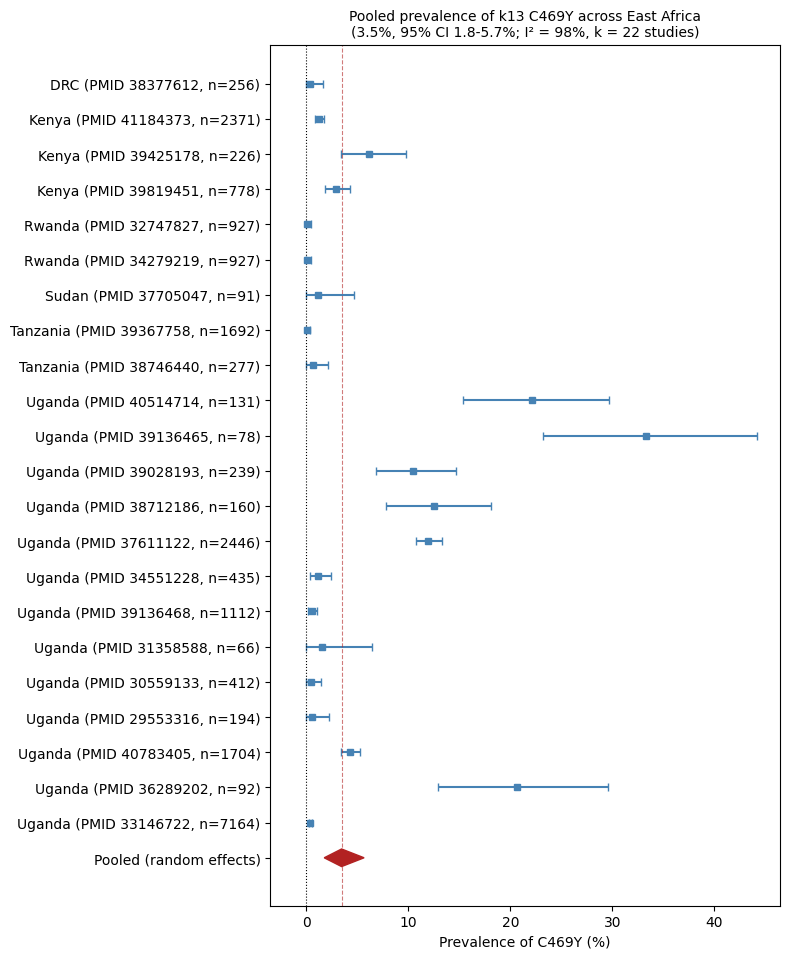

In [6]:
"""
k13_meta_analysis.py
---------------------
Self-contained script: loads the k13 validated-mutations dataset, cleans it,
and runs a random-effects meta-analysis of proportions (pooled prevalence)
for one mutation at a time, with a forest plot.

Everything is in ONE file on purpose -- no other local modules needed.
Just put this script and your Excel file in the same folder and run it.

Method: Freeman-Tukey double arcsine transformation (Freeman & Tukey, 1950)
with DerSimonian-Laird (1986) random-effects pooling, back-transformed using
the harmonic-mean method of Miller (1978). This mirrors R's
meta::metaprop(sm="PFT", method.tau="DL").
"""

import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# =================================================================
# SETTINGS -- change these two lines as needed
# =================================================================
RAW_PATH = "K13_validated_v8.xlsx"   # must be in the same folder as this script
MUTATION = "C469Y"                    # change to "R561H", "C469Y", "R622I", "P574L", "A675V" etc.


# =================================================================
# STEP 1-2: Load raw data
# =================================================================
def load_raw(path=RAW_PATH):
    return pd.read_excel(path, sheet_name="Sheet1")


# =================================================================
# STEP 3: Clean year_sample into a single numeric year
# =================================================================
def parse_year(val):
    """Return the mean of all 4-digit years found in a year_sample field.
    Used for general reference only (not for the trend/meta-regression, which
    uses parse_year_single_only below)."""
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if s.lower() == "missing":
        return np.nan
    s = s.replace("\u2013", "-").replace("\u2014", "-")
    years = [int(y) for y in re.findall(r"(?:19|20)\d{2}", s)]
    if not years:
        return np.nan
    return sum(years) / len(years)


def parse_year_single_only(val):
    """Return the year ONLY if the field reports a single, unambiguous
    sampling year. Records reporting a range (e.g. "2015-2016") or a list of
    multiple years (e.g. "2011, 2012, 2015") are excluded (return NaN) rather
    than averaged/collapsed to a midpoint -- per PI feedback, averaging a
    multi-year group into one artificial year is not a meaningful data point
    for a year-by-year trend analysis and should simply be dropped from the
    meta-regression rather than mis-represented as a precise single year.
    """
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if s.lower() == "missing":
        return np.nan
    s = s.replace("\u2013", "-").replace("\u2014", "-")
    years = sorted(set(int(y) for y in re.findall(r"(?:19|20)\d{2}", s)))
    if len(years) != 1:
        return np.nan
    return float(years[0])


# =================================================================
# STEP 4: Clean numerator/denominator (shared by all downstream steps)
# =================================================================
def clean_data(df):
    df = df.copy()
    df["year_sample_clean"] = df["year_sample"].apply(parse_year)
    df["year_sample_single"] = df["year_sample"].apply(parse_year_single_only)
    df["samples_genotyped"] = pd.to_numeric(df["samples_genotyped"], errors="coerce")
    df["raw_count"] = pd.to_numeric(df["raw_count"], errors="coerce")

    mut = df["k13_validated_mutations"].astype(str).str.strip()
    valid_mut = ~mut.isin(["-", "0", "-\t", "nan"])
    has_counts = (
        df["raw_count"].notna()
        & df["samples_genotyped"].notna()
        & (df["samples_genotyped"] > 0)
    )
    clean = df[valid_mut & has_counts].copy()
    clean["k13_validated_mutations"] = mut[valid_mut & has_counts]
    return clean


# =================================================================
# STEP 5: Collapse to one row per study per mutation (for Steps 7-9)
# =================================================================
def study_level_table(clean, mutation):
    sub = clean[clean["k13_validated_mutations"] == mutation]
    table = sub.groupby("pmid").agg(
        country=("country", "first"),
        x=("raw_count", "sum"),
        n=("samples_genotyped", "sum"),
        year_mid=("year_sample_clean", "mean"),
        n_timepoints=("raw_count", "size"),
    ).reset_index()
    return table.sort_values("country").reset_index(drop=True)


def clean_and_collapse(df, mutation):
    """Convenience wrapper kept for backward compatibility: clean the raw
    dataframe and collapse to one row per study for the given mutation."""
    clean = clean_data(df)
    return study_level_table(clean, mutation)


# =================================================================
# STEP 7: Meta-analysis of proportions (Freeman-Tukey + DerSimonian-Laird)
# =================================================================
def freeman_tukey_transform(x, n):
    x = np.asarray(x, dtype=float)
    n = np.asarray(n, dtype=float)
    phi = 0.5 * (np.arcsin(np.sqrt(x / (n + 1))) +
                 np.arcsin(np.sqrt((x + 1) / (n + 1))))
    var_phi = 1.0 / (4.0 * n + 2.0)
    return phi, var_phi


def back_transform_pft(phi, n_harmonic):
    # The double-arcsine transform of a proportion x/n is only ever defined
    # for x between 0 and n. That means, for a given (harmonic-mean) n, phi
    # itself has an achievable floor (x=0) and ceiling (x=n) -- phi values
    # outside that range cannot correspond to any real proportion for that n.
    # A pooled or CI value can land outside this range (e.g. the lower CI
    # bound pushed below the x=0 floor by high between-study variance), and
    # the general Miller (1978) formula becomes numerically unstable there
    # (it can return values like 0.5 instead of ~0). We clamp to the
    # achievable range first, which is both the correct interpretation (a
    # proportion can't be estimated more precisely than "close to 0/1") and
    # numerically stable.
    phi_floor = 0.5 * np.arcsin(np.sqrt(1.0 / (n_harmonic + 1)))          # x=0
    phi_ceiling = 0.5 * (np.arcsin(np.sqrt(n_harmonic / (n_harmonic + 1))) + np.pi / 2)  # x=n

    if phi <= phi_floor:
        return 0.0
    if phi >= phi_ceiling:
        return 1.0

    sin2t = np.sin(2 * phi)
    inner = sin2t + (sin2t - 1.0 / sin2t) / n_harmonic
    inner = np.clip(inner, -1, 1)
    return 0.5 * (1 - np.sign(np.cos(2 * phi)) * np.sqrt(1 - inner ** 2))


def dersimonian_laird(phi, var_phi):
    k = len(phi)
    w_fixed = 1.0 / var_phi
    mean_fixed = np.sum(w_fixed * phi) / np.sum(w_fixed)

    Q = np.sum(w_fixed * (phi - mean_fixed) ** 2)
    df = k - 1
    C = np.sum(w_fixed) - np.sum(w_fixed ** 2) / np.sum(w_fixed)
    tau2 = max(0.0, (Q - df) / C) if C > 0 else 0.0

    w_random = 1.0 / (var_phi + tau2)
    pooled_phi = np.sum(w_random * phi) / np.sum(w_random)
    se_pooled_phi = np.sqrt(1.0 / np.sum(w_random))

    I2 = max(0.0, (Q - df) / Q) * 100 if Q > 0 else 0.0
    p_het = 1 - stats.chi2.cdf(Q, df) if df > 0 else np.nan

    return {
        "k": k, "pooled_phi": pooled_phi, "se_pooled_phi": se_pooled_phi,
        "tau2": tau2, "Q": Q, "df": df, "I2": I2, "p_heterogeneity": p_het,
        "weights_random": w_random,
    }


def metaprop(x, n, ci_level=0.95):
    x = np.asarray(x, dtype=float)
    n = np.asarray(n, dtype=float)

    phi, var_phi = freeman_tukey_transform(x, n)
    res = dersimonian_laird(phi, var_phi)

    z = stats.norm.ppf(0.5 + ci_level / 2)
    phi_lo = res["pooled_phi"] - z * res["se_pooled_phi"]
    phi_hi = res["pooled_phi"] + z * res["se_pooled_phi"]

    n_harm = stats.hmean(n)
    pooled_p = back_transform_pft(res["pooled_phi"], n_harm)
    ci_lo = back_transform_pft(phi_lo, n_harm)
    ci_hi = back_transform_pft(phi_hi, n_harm)

    study_p = np.array([back_transform_pft(p, ni) for p, ni in zip(phi, n)])
    study_se_phi = np.sqrt(var_phi)
    study_lo = np.array([back_transform_pft(p - z * se, ni)
                          for p, se, ni in zip(phi, study_se_phi, n)])
    study_hi = np.array([back_transform_pft(p + z * se, ni)
                          for p, se, ni in zip(phi, study_se_phi, n)])

    return {
        "x": x, "n": n,
        "study_p": study_p, "study_lo": study_lo, "study_hi": study_hi,
        "pooled_p": pooled_p, "ci_lo": ci_lo, "ci_hi": ci_hi,
        "tau2": res["tau2"], "I2": res["I2"], "Q": res["Q"], "df": res["df"],
        "p_heterogeneity": res["p_heterogeneity"], "k": res["k"],
    }


# =================================================================
# STEP 8: Forest plot
# =================================================================
def forest_plot(table, result, mutation):
    k = result["k"]
    fig, ax = plt.subplots(figsize=(8, 0.35 * k + 2))

    y_pos = np.arange(k, 0, -1)
    study_labels = [f"{row.country} (PMID {row.pmid}, n={int(row.n)})"
                    for row in table.itertuples()]

    lo_err = np.clip((result["study_p"] - result["study_lo"]) * 100, 0, None)
    hi_err = np.clip((result["study_hi"] - result["study_p"]) * 100, 0, None)
    ax.errorbar(
        result["study_p"] * 100, y_pos,
        xerr=[lo_err, hi_err],
        fmt="s", color="steelblue", ecolor="steelblue", capsize=3, markersize=5,
        label="Study estimate (95% CI)",
    )

    pooled_y = 0
    diamond_x = [result["ci_lo"] * 100, result["pooled_p"] * 100,
                 result["ci_hi"] * 100, result["pooled_p"] * 100]
    diamond_y = [pooled_y, pooled_y + 0.25, pooled_y, pooled_y - 0.25]
    ax.fill(diamond_x, diamond_y, color="firebrick")

    ax.set_yticks(list(y_pos) + [pooled_y])
    ax.set_yticklabels(study_labels + ["Pooled (random effects)"])
    ax.axvline(result["pooled_p"] * 100, color="firebrick", linestyle="--",
               linewidth=0.8, alpha=0.6)
    ax.set_xlabel(f"Prevalence of {mutation} (%)")
    ax.set_title(
        f"Pooled prevalence of k13 {mutation} across East Africa\n"
        f"({result['pooled_p']*100:.1f}%, 95% CI {result['ci_lo']*100:.1f}-"
        f"{result['ci_hi']*100:.1f}%; I\u00b2 = {result['I2']:.0f}%, k = {k} studies)",
        fontsize=10,
    )
    xmax = max(np.max(result["study_hi"]) * 100, result["ci_hi"] * 100)
    xpad = max(xmax * 0.08, 1.0)  # at least a little padding even for very small-scale mutations
    ax.set_xlim(left=-xpad, right=xmax * 1.05)
    ax.axvline(0, color="black", linewidth=0.8, linestyle=":")
    plt.tight_layout()
    outname = f"forest_{mutation}.png"
    plt.savefig(outname, dpi=200)
    print(f"Forest plot saved to {outname}")


# =================================================================
# STEP 9: Country-subgroup pooling + test for subgroup differences
# =================================================================
MIN_STUDIES_TO_POOL = 3  # countries with fewer studies are reported descriptively only


def subgroup_by_country(table, min_studies=MIN_STUDIES_TO_POOL):
    """Run a separate metaprop() within each country that has enough studies.

    Countries with fewer than `min_studies` studies are still returned (so you
    can see their raw data) but are flagged as not pooled -- their single-study
    or two-study "prevalence" would be unstable and is not a meta-analytic
    estimate.

    Returns a DataFrame with one row per country.
    """
    rows = []
    for country, sub in table.groupby("country"):
        x = sub["x"].values
        n = sub["n"].values
        k = len(sub)
        if k >= min_studies:
            res = metaprop(x, n)
            rows.append({
                "country": country, "k_studies": k, "pooled": True,
                "prevalence_pct": res["pooled_p"] * 100,
                "ci_lo": res["ci_lo"] * 100, "ci_hi": res["ci_hi"] * 100,
                "I2_pct": res["I2"], "tau2": res["tau2"],
            })
        else:
            # descriptive only: naive combined proportion, no valid CI/I2
            naive_p = 100 * x.sum() / n.sum()
            rows.append({
                "country": country, "k_studies": k, "pooled": False,
                "prevalence_pct": naive_p,
                "ci_lo": np.nan, "ci_hi": np.nan,
                "I2_pct": np.nan, "tau2": np.nan,
            })
    return pd.DataFrame(rows).sort_values("prevalence_pct", ascending=False).reset_index(drop=True)


def subgroup_heterogeneity_test(table):
    """Fixed-effect Q-test for whether pooled prevalence differs across
    country subgroups (analogous to a one-way ANOVA in meta-analysis).

    Q_between = Q_total - Q_within, tested against a chi-square distribution
    with (number of countries - 1) degrees of freedom.

    Note: countries with only 1 study contribute 0 to Q_within (df = 0) but
    are still included in Q_total and in the group count -- this is standard,
    but the test is more reliable when most subgroups have >=2 studies.
    """
    phi, var_phi = freeman_tukey_transform(table["x"].values, table["n"].values)
    w = 1.0 / var_phi

    grand_mean = np.sum(w * phi) / np.sum(w)
    Q_total = np.sum(w * (phi - grand_mean) ** 2)

    Q_within = 0.0
    df_within = 0
    countries = table["country"].unique()
    table = table.copy()
    table["_phi"] = phi
    table["_w"] = w

    for country in countries:
        sub = table[table["country"] == country]
        if len(sub) < 2:
            continue  # 0 degrees of freedom, contributes 0 to Q_within
        mean_g = np.sum(sub["_w"] * sub["_phi"]) / np.sum(sub["_w"])
        Q_within += np.sum(sub["_w"] * (sub["_phi"] - mean_g) ** 2)
        df_within += len(sub) - 1

    Q_between = Q_total - Q_within
    df_between = len(countries) - 1
    p_between = 1 - stats.chi2.cdf(Q_between, df_between) if df_between > 0 else np.nan

    return {
        "Q_between": Q_between, "df_between": df_between, "p_between": p_between,
        "Q_within": Q_within, "df_within": df_within,
        "n_countries": len(countries),
    }


def country_forest_plot(table, mutation, min_studies=MIN_STUDIES_TO_POOL):
    """Forest plot grouped by country, with a pooled diamond per country
    that has enough studies, plus the overall pooled diamond at the bottom."""
    table = table.copy()
    # order countries by their (pooled or naive) prevalence, descending
    country_summary = subgroup_by_country(table, min_studies)
    country_order = country_summary["country"].tolist()

    table["_country_rank"] = table["country"].map({c: i for i, c in enumerate(country_order)})
    table = table.sort_values(["_country_rank", "n"], ascending=[True, False]).reset_index(drop=True)

    overall = metaprop(table["x"].values, table["n"].values)

    # build the y-axis: each study row, plus a subgroup-pooled diamond row
    # after each country's studies, plus the overall diamond at the very bottom
    y = 0
    y_positions, labels, kinds = [], [], []  # kinds: "study" or "diamond"
    diamonds = []  # (y, lo, mid, hi) for country diamonds
    study_rows = []  # indices into table, in plotted order

    for country in country_order:
        sub = table[table["country"] == country]
        for idx in sub.index:
            y += 1
            y_positions.append(y)
            labels.append(f"  {sub.loc[idx, 'country']} (PMID {sub.loc[idx, 'pmid']}, n={int(sub.loc[idx, 'n'])})")
            kinds.append("study")
            study_rows.append(idx)
        y += 1
        row = country_summary[country_summary["country"] == country].iloc[0]
        if row["pooled"]:
            diamonds.append((y, row["ci_lo"], row["prevalence_pct"], row["ci_hi"]))
            labels.append(f"  {country} subgroup pooled (k={int(row['k_studies'])})")
        else:
            diamonds.append((y, np.nan, row["prevalence_pct"], np.nan))
            labels.append(f"  {country} (k={int(row['k_studies'])}, not pooled)")
        y_positions.append(y)
        kinds.append("diamond")
        y += 1  # gap before next country

    y += 1
    overall_y = y
    y_positions.append(overall_y)
    labels.append("OVERALL pooled (random effects)")
    kinds.append("overall")

    fig_height = 0.32 * len(y_positions) + 2
    fig, ax = plt.subplots(figsize=(9, fig_height))

    study_p = overall["study_p"]
    study_lo = overall["study_lo"]
    study_hi = overall["study_hi"]

    for plot_pos, table_idx in zip([yp for yp, k in zip(y_positions, kinds) if k == "study"], study_rows):
        i = table.index.get_loc(table_idx)
        lo_err = max((study_p[i] - study_lo[i]) * 100, 0)
        hi_err = max((study_hi[i] - study_p[i]) * 100, 0)
        ax.errorbar(study_p[i] * 100, plot_pos, xerr=[[lo_err], [hi_err]],
                    fmt="s", color="steelblue", ecolor="steelblue",
                    capsize=3, markersize=5)

    for (dy, lo, mid, hi) in diamonds:
        if not np.isnan(lo):
            dx = [lo, mid, hi, mid]
            dyy = [dy, dy + 0.25, dy, dy - 0.25]
            ax.fill(dx, dyy, color="darkorange")
        else:
            ax.plot(mid, dy, marker="D", color="gray", markersize=6)

    ax.fill(
        [overall["ci_lo"] * 100, overall["pooled_p"] * 100, overall["ci_hi"] * 100, overall["pooled_p"] * 100],
        [overall_y, overall_y + 0.3, overall_y, overall_y - 0.3],
        color="firebrick",
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels)
    ax.set_xlabel(f"Prevalence of {mutation} (%)")
    ax.set_title(f"k13 {mutation} prevalence by country\n"
                 f"(overall {overall['pooled_p']*100:.1f}%, 95% CI "
                 f"{overall['ci_lo']*100:.1f}-{overall['ci_hi']*100:.1f}%; "
                 f"I\u00b2 = {overall['I2']:.0f}%)", fontsize=10)
    xmax = max(np.nanmax(study_hi) * 100, overall["ci_hi"] * 100)
    xpad = max(xmax * 0.08, 1.0)
    ax.set_xlim(left=-xpad, right=xmax * 1.05)
    ax.axvline(0, color="black", linewidth=0.8, linestyle=":")
    plt.tight_layout()
    outname = f"forest_{mutation}_by_country.png"
    plt.savefig(outname, dpi=200)
    plt.close(fig)
    print(f"Country-stratified forest plot saved to {outname}")


# =================================================================
# STEP 10: Meta-regression on year (test for a trend over time)
# =================================================================
def year_level_table(clean, mutation):
    """Build the table used for the YEAR META-REGRESSION.

    Unlike study_level_table() (used for Steps 7-9, which collapses each
    study to a single row so every study is counted once), this keeps
    year-to-year variation: rows are aggregated by (study, year) rather than
    by study alone, so a study surveilled across several years contributes
    one data point per year instead of being collapsed to a single average.

    Per PI feedback: records where year_sample was reported as a range
    (e.g. "2015-2016") or a list of multiple years (e.g. "2011, 2012, 2015")
    are EXCLUDED from this table entirely, rather than averaged into an
    artificial midpoint year. Averaging misrepresents a multi-year group as
    a single precise year, which is not meaningful for a year-by-year trend
    plot/regression. Only rows with a genuine, unambiguous single sampling
    year (year_sample_single) are retained here.

    Caveat to state in the manuscript: rows from the same study across
    different years are still not fully independent (they share a common
    study-level effect -- population, lab, genotyping protocol). A three-level
    meta-analysis (random effects for study AND for year-within-study) would
    handle this more rigorously; the model here is a simpler two-level
    approximation and should be reported as such.
    """
    sub = clean[clean["k13_validated_mutations"] == mutation]
    sub = sub.dropna(subset=["year_sample_single"])
    table = sub.groupby(["pmid", "year_sample_single"]).agg(
        country=("country", "first"),
        x=("raw_count", "sum"),
        n=("samples_genotyped", "sum"),
    ).reset_index()
    table = table.rename(columns={"year_sample_single": "year_sample_clean"})
    return table.sort_values("year_sample_clean").reset_index(drop=True)


def meta_regression(phi, var_phi, moderator):
    """Mixed-effects meta-regression of phi on a single continuous moderator
    (e.g. year), using a DerSimonian-Laird-style (method-of-moments) tau^2
    estimator generalized to regression via the hat-matrix correction --
    i.e. the same family of method as R's metafor::rma(method="DL") with a
    moderator, computed directly here since metafor/statsmodels are not
    available in this environment.

    Returns intercept & slope (on the phi/arcsine scale), their SEs, a
    Wald z-test and p-value for the slope, tau^2, and the fitted values
    (for plotting a regression line).
    """
    k = len(phi)
    X = np.column_stack([np.ones(k), moderator])
    w = 1.0 / var_phi

    XtWX = X.T @ (X * w[:, None])
    XtWX_inv = np.linalg.inv(XtWX)
    beta_fixed = XtWX_inv @ (X.T @ (w * phi))
    fitted_fixed = X @ beta_fixed

    Q_E = np.sum(w * (phi - fitted_fixed) ** 2)
    df_resid = k - X.shape[1]

    XtW2X = X.T @ (X * (w ** 2)[:, None])
    C = np.sum(w) - np.trace(XtWX_inv @ XtW2X)
    tau2 = max(0.0, (Q_E - df_resid) / C) if C > 0 else 0.0

    w_r = 1.0 / (var_phi + tau2)
    XtWrX = X.T @ (X * w_r[:, None])
    XtWrX_inv = np.linalg.inv(XtWrX)
    beta_random = XtWrX_inv @ (X.T @ (w_r * phi))
    se_random = np.sqrt(np.diag(XtWrX_inv))
    fitted_random = X @ beta_random

    z_slope = beta_random[1] / se_random[1]
    p_slope = 2 * (1 - stats.norm.cdf(abs(z_slope)))

    return {
        "intercept": beta_random[0], "slope": beta_random[1],
        "se_intercept": se_random[0], "se_slope": se_random[1],
        "z_slope": z_slope, "p_slope": p_slope,
        "tau2": tau2, "Q_E": Q_E, "df_resid": df_resid,
        "fitted_phi": fitted_random,
    }


def run_year_meta_regression(clean, mutation, n_harm_default=None):
    """Full pipeline: build the year-level table, transform, fit the
    meta-regression, and back-transform the fitted trend line for plotting.
    Returns (table, reg_result, study_p) or None if too few data points.
    """
    table = year_level_table(clean, mutation)
    table = table[table["n"] > 0].reset_index(drop=True)
    if len(table) < 6:
        return None  # too few year-level points for a stable regression

    phi, var_phi = freeman_tukey_transform(table["x"].values, table["n"].values)
    reg = meta_regression(phi, var_phi, table["year_sample_clean"].values)

    n_harm = stats.hmean(table["n"].values)
    study_p = np.array([back_transform_pft(p, ni) for p, ni in zip(phi, table["n"].values)])
    fitted_p = np.array([back_transform_pft(fp, n_harm) for fp in reg["fitted_phi"]])

    return table, reg, study_p, fitted_p


def year_trend_plot(table, reg, study_p, fitted_p, mutation):
    """Bubble plot: prevalence vs year, point size = sample size, with the
    fitted meta-regression trend line."""
    fig, ax = plt.subplots(figsize=(8, 5))

    sizes = 20 + 180 * (table["n"] / table["n"].max())
    ax.scatter(table["year_sample_clean"], study_p * 100, s=sizes,
               alpha=0.6, color="steelblue", edgecolor="white", linewidth=0.5,
               label="Study-year estimate (size = sample size)")

    order = np.argsort(table["year_sample_clean"].values)
    ax.plot(table["year_sample_clean"].values[order], fitted_p[order] * 100,
            color="firebrick", linewidth=2, label="Fitted trend (meta-regression)")

    sig = "significant" if reg["p_slope"] < 0.05 else "not significant"
    ax.set_xlabel("Year of sample collection")
    ax.set_ylabel(f"Prevalence of {mutation} (%)")
    ax.set_title(
        f"k13 {mutation}: prevalence trend over time\n"
        f"slope p = {reg['p_slope']:.3g} ({sig}), "
        f"\u03c4\u00b2 = {reg['tau2']:.4f}, k = {len(table)} study-year points",
        fontsize=10,
    )
    ax.legend(fontsize=8, loc="upper left")
    plt.tight_layout()
    outname = f"trend_{mutation}.png"
    plt.savefig(outname, dpi=200)
    plt.close(fig)
    print(f"Year trend plot saved to {outname}")


# =================================================================
# RUN
# =================================================================
if __name__ == "__main__":
    df = load_raw()
    print(f"Loaded {len(df)} rows, {df['pmid'].nunique()} unique studies.\n")

    table = clean_and_collapse(df, MUTATION)
    print(f"=== {MUTATION}: {len(table)} studies (after collapsing) ===")
    print(table[["pmid", "country", "x", "n", "n_timepoints"]].to_string(index=False))

    result = metaprop(table["x"].values, table["n"].values)

    print()
    print(f"Pooled prevalence: {result['pooled_p']*100:.1f}% "
          f"(95% CI {result['ci_lo']*100:.1f}-{result['ci_hi']*100:.1f}%)")
    print(f"tau^2 = {result['tau2']:.4f}, I^2 = {result['I2']:.1f}%, "
          f"Q({result['df']}) = {result['Q']:.1f}, p_het = {result['p_heterogeneity']:.4g}")

    forest_plot(table, result, MUTATION)

    print()
    print(f"=== {MUTATION}: country subgroups ===")
    subgroups = subgroup_by_country(table)
    print(subgroups.to_string(index=False))

    het_test = subgroup_heterogeneity_test(table)
    print()
    print(f"Test for subgroup differences: Q_between({het_test['df_between']}) = "
          f"{het_test['Q_between']:.2f}, p = {het_test['p_between']:.4g} "
          f"across {het_test['n_countries']} countries")

    country_forest_plot(table, MUTATION)

    # --- Step 10: year meta-regression ---
    clean = clean_data(df)
    year_result = run_year_meta_regression(clean, MUTATION)
    if year_result is None:
        print(f"\nToo few year-labeled study-year points for {MUTATION} "
              f"to run a meta-regression (need at least 6).")
    else:
        year_table, reg, study_p, fitted_p = year_result
        print()
        print(f"=== {MUTATION}: year meta-regression ({len(year_table)} study-year points) ===")
        print(f"Slope = {reg['slope']:.5f} phi-units/year (SE {reg['se_slope']:.5f}), "
              f"z = {reg['z_slope']:.2f}, p = {reg['p_slope']:.4g}")
        print(f"tau^2 (residual) = {reg['tau2']:.5f}, "
              f"Q_E({reg['df_resid']}) = {reg['Q_E']:.1f}")
        direction = "increasing" if reg["slope"] > 0 else "decreasing"
        sig = "statistically significant" if reg["p_slope"] < 0.05 else "not statistically significant"
        print(f"-> Prevalence trend over time is {direction} and {sig} (p={reg['p_slope']:.3g}).")
        year_trend_plot(year_table, reg, study_p, fitted_p, MUTATION)